# Primera Red Neuronal Profunda
En este notebook se aplicara todo lo visto durante el primer parcial de Aprendizaje Profundo. <br>
Para la aplicación de estos conocimientos se ha optado por 



## Metricas realizadas con otros métodos
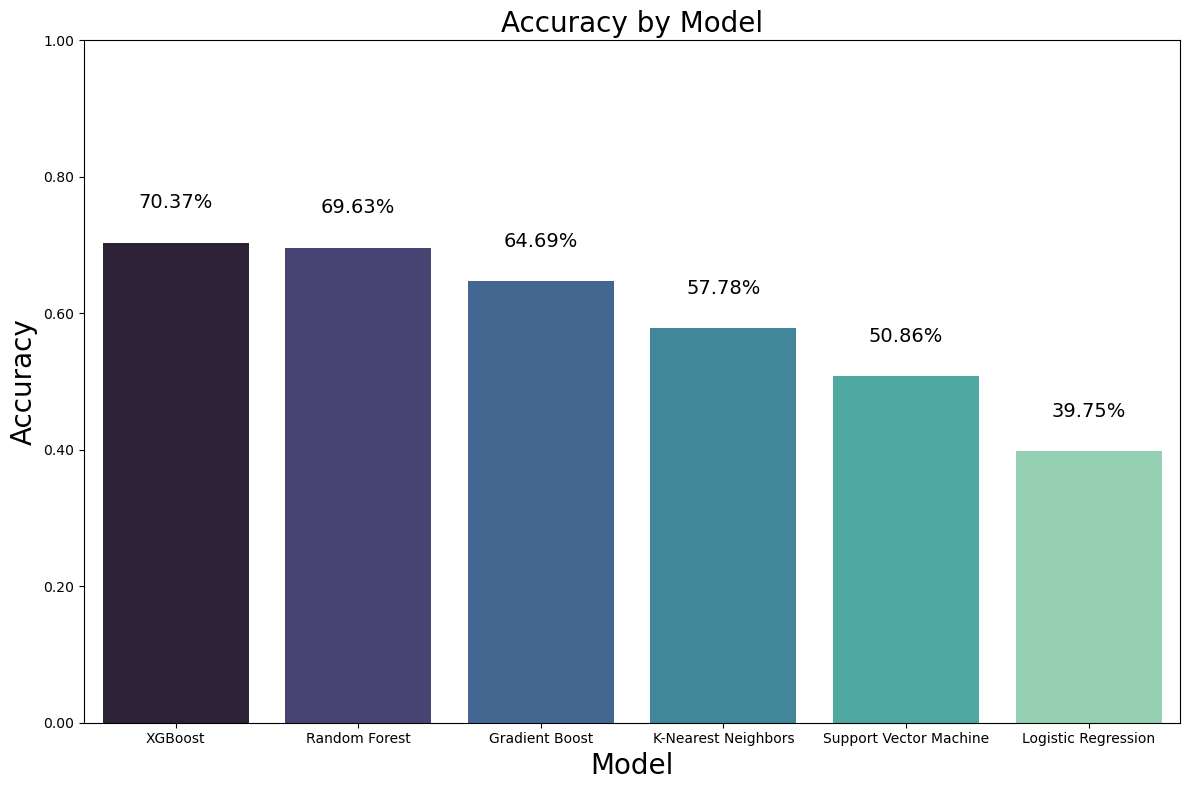

## Liberias y dataset

In [10]:
# Librerias  
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
# Preprocesamiento
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
# TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers, callbacks

### Importación del dataset y target

In [3]:
# Carga del conjunto de datos con datos explicitos
df = pd.read_csv('Data/CorporateCredit.csv',
dtype={
        'Rating Agency': 'category',
        'Rating': 'category',
        'Binary Rating': 'boolean',
        'SIC Code': 'string',
        'Sector': 'category',
        'Ticker': 'string'
    }
)
target = 'Rating'

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7805 entries, 0 to 7804
Data columns (total 25 columns):
 #   Column                         Non-Null Count  Dtype   
---  ------                         --------------  -----   
 0   Rating Agency                  7805 non-null   category
 1   Corporation                    7805 non-null   str     
 2   Rating                         7805 non-null   category
 3   Rating Date                    7805 non-null   str     
 4   CIK                            7805 non-null   int64   
 5   Binary Rating                  7805 non-null   boolean 
 6   SIC Code                       7805 non-null   string  
 7   Sector                         7805 non-null   category
 8   Ticker                         7805 non-null   string  
 9   Current Ratio                  7805 non-null   float64 
 10  Long-term Debt / Capital       7805 non-null   float64 
 11  Debt/Equity Ratio              7805 non-null   float64 
 12  Gross Margin                   7805 non-null 

C:\Users\kevin\AppData\Local\Temp\ipykernel_2896\1897345634.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


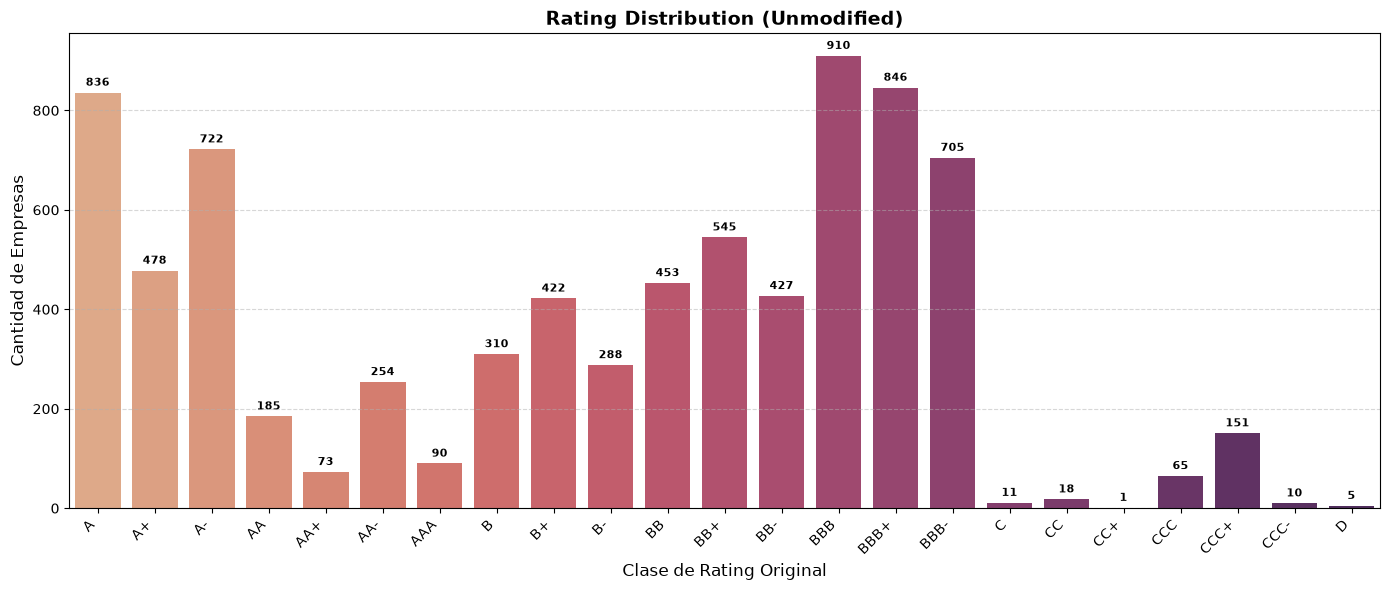

In [5]:
# 2. Configuración de lienzo ampliado para albergar 23 columnas
fig, ax = plt.subplots(figsize=(14, 6))

# 3. Gráfico de distribución original
sns.countplot(
    data=df, 
    x=target,  
    palette="flare", 
    ax=ax
)

# 4. Formato y etiquetas
ax.set_title("Rating Distribution (Unmodified)", fontsize=14, fontweight='bold')
ax.set_xlabel("Clase de Rating Original", fontsize=12)
ax.set_ylabel("Cantidad de Empresas", fontsize=12)

# Rotación de etiquetas a 45 grados y cuadrícula vertical de soporte
plt.xticks(rotation=45, ha='right')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# 5. Anotación numérica sobre cada barra (manejando clases con 0 registros)
for p in ax.patches:
    height = p.get_height()
    if not np.isnan(height) and height > 0:
        ax.annotate(
            f'{int(height)}', 
            (p.get_x() + p.get_width() / 2., height),
            ha='center', va='bottom', 
            xytext=(0, 3), textcoords='offset points',
            fontsize=8, fontweight='bold'
        )

plt.tight_layout()
plt.show()

## Preprocesamiento de los datos

In [6]:
FUSIONAR_DEFAULT = True   # True -> 8 clases (D dentro de CCC-C) | False -> 9 clases

columnas_descarte = ['CIK', 'Corporation', 'Binary Rating', 'Rating Date', 'Ticker', 'SIC Code']
df = df.drop(columns=columnas_descarte, errors='ignore')
n_antes = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicados eliminados: {n_antes - len(df)} (quedan {len(df)} filas)")

RATING_MAP = {
    'AAA': 0, 'AA+': 0, 'AA': 0, 'AA-': 0,
    'A+': 1,
    'A': 2,
    'A-': 3,
    'BBB+': 4, 'BBB': 4, 'BBB-': 4,
    'BB+': 5, 'BB': 5, 'BB-': 5,
    'B+': 6, 'B': 6, 'B-': 6,
    'CCC+': 7, 'CCC': 7, 'CCC-': 7, 'CC+': 7, 'CC': 7, 'C': 7,
    'D': 7 if FUSIONAR_DEFAULT else 8
}

CLASS_NAMES = {
    0: 'AAA/AA', 1: 'A+', 2: 'A', 3: 'A-', 4: 'BBB', 5: 'BB', 6: 'B',
    7: 'CCC-C+D' if FUSIONAR_DEFAULT else 'CCC-C', 8: 'D'
}

df[target] = df[target].astype(str).map(RATING_MAP)

nulos_generados = df[target].isnull().sum()
if nulos_generados > 0:
    print(f"Advertencia: Se descartaron {nulos_generados} registros sin mapeo.")
    df = df.dropna(subset=[target]).copy()
df[target] = df[target].astype(int)

X_ORDER = sorted(df[target].unique())
X_LABELS = [CLASS_NAMES[i] for i in X_ORDER]
print(f"Clases finales: {len(X_ORDER)} -> {X_LABELS}")
print(df[target].value_counts().sort_index().to_string())

X = df.drop(columns=[target])
y = df[target]

Duplicados eliminados: 2551 (quedan 5254 filas)
Clases finales: 8 -> ['AAA/AA', 'A+', 'A', 'A-', 'BBB', 'BB', 'B', 'CCC-C+D']
Rating
0     352
1     254
2     535
3     434
4    1672
5    1038
6     767
7     202


## Train, Dev y Test

In [7]:
# 7. Partición Estratificada Tridimensional (80% Train, 10% Dev, 10% Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
strat_temp = y_temp if y_temp.value_counts().min() >= 2 else None
if strat_temp is None:
    print("Aviso: alguna clase tiene <2 muestras en el bloque temporal; Dev/Test sin estratificar.")
X_dev, X_test, y_dev, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=strat_temp
)

In [8]:
# 8. Identificación de Columnas para el Pipeline
columnas_categoricas = ['Rating Agency', 'Sector']
columnas_numericas = X.select_dtypes(include=['float64']).columns.tolist()


### Normalización de los datos
**Estandarización Z-Score (StandardScaler)** 
Transforma cada característica numérica para que tenga media $\mu = 0$ y desviación estándar $\sigma = 1$:

$$z = \frac{x - \mu}{\sigma}$$

Razón de selección: Como se observó en el desglose estadístico (.describe()), existen ratios con valores atípicos extremos como ROE ($\min = -11,258.21$, $\max = 7,038.46$). La estandarización preserve la distancia relativa de los datos extremos sin comprimir la varianza del resto de las observaciones.

In [11]:
# 9. Pipeline de Transformación de Características
preprocesador = ColumnTransformer(
    transformers=[
        ('num', RobustScaler(), columnas_numericas),
        ('cat', OneHotEncoder(drop=None, sparse_output=False, handle_unknown='ignore'), columnas_categoricas)
    ]
)

In [12]:
df.head()


,Rating Agency,Rating,Sector,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
0,Standard & Poor's Ratings Services,3,Utils,1.1507,0.4551,0.8847,77.6230,19.4839,19.4839,28.9834,13.6093,8.3224,0.3173,8.1724,8.1978,2.6385,4.4530,1.9957,-0.1333
1,Standard & Poor's Ratings Services,0,BusEq,1.1129,0.0072,0.0073,43.6619,19.8327,19.8327,23.9379,20.8699,13.5690,0.3324,22.0354,47.2858,4.4944,21.8765,0.2501,0.3132
2,Standard & Poor's Ratings Services,4,Shops,1.9276,0.2924,0.4255,11.9008,3.3173,3.3173,3.6338,3.0536,2.1418,2.4620,13.6376,16.7991,5.2731,9.6494,-7.6079,-7.3231
3,Standard & Poor's Ratings Services,0,Utils,0.8358,0.4708,0.9491,64.5096,18.4549,18.4549,27.9377,15.1135,9.0246,0.2946,9.6412,9.7015,2.6583,5.1018,1.7438,-0.8999
4,Standard & Poor's Ratings Services,2,Shops,1.2931,0.2644,0.4036,3.8385,1.3269,1.3269,1.5847,1.2304,0.6518,4.9276,11.1256,19.4184,2.9364,8.1844,1.9725,2.4174


In [10]:
df.describe()

,Rating,Current Ratio,Long-term Debt / Capital,Debt/Equity Ratio,Gross Margin,Operating Margin,EBIT Margin,EBITDA Margin,Pre-Tax Profit Margin,Net Profit Margin,Asset Turnover,ROE - Return On Equity,Return On Tangible Equity,ROA - Return On Assets,ROI - Return On Investment,Operating Cash Flow Per Share,Free Cash Flow Per Share
count,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000,5254.000000
mean,3.905596,1.922544,0.463649,-0.261848,42.174783,11.002326,11.053951,19.662857,8.044245,5.426744,0.855888,11.605905,21.198408,4.377956,6.872244,0.561743,0.038001
std,1.765264,1.896909,2.945334,39.748907,23.869516,27.208801,27.221122,25.783220,29.365457,25.559534,0.695256,243.781916,484.605006,9.885252,24.514138,6.943983,7.735474
min,0.000000,0.174900,-86.363600,-1473.098000,-87.684000,-461.787800,-461.787800,-360.816900,-476.010000,-414.824800,0.068400,-11258.210000,-14023.260000,-226.442500,-745.454500,-91.330200,-130.665800
25%,3.000000,1.077500,0.286300,0.412700,22.104500,5.856100,5.896575,10.711300,3.621800,2.435900,0.400750,5.594300,-11.052300,2.243000,3.372325,-0.463800,-0.760600
50%,4.000000,1.513750,0.428950,0.760650,39.102600,11.903200,11.976200,18.168200,9.409600,6.726050,0.666100,12.024200,10.335100,4.629700,7.191750,0.230000,0.107400
75%,5.000000,2.172100,0.547650,1.218800,59.467650,19.079200,19.119125,30.410975,16.125600,11.895475,1.045675,20.009300,26.007375,7.768100,12.361500,1.111200,1.005500
max,7.000000,34.076800,171.500000,194.375000,100.000000,93.993000,93.993000,286.493500,221.289400,219.390300,8.503900,7038.461000,9882.979000,114.716900,466.666700,282.192100,107.737700


In [11]:
# 10. Ajuste e Inferencia en Tensores Disjuntos
X_train_proc = preprocesador.fit_transform(X_train)
X_dev_proc = preprocesador.transform(X_dev)
X_test_proc = preprocesador.transform(X_test)

print(f"Número de clases objetivo: {len(X_ORDER)}")
print(f"Dimensiones de X_train_proc: {X_train_proc.shape}")
print(f"Dimensiones de X_dev_proc: {X_dev_proc.shape}")
print(f"Dimensiones de X_test_proc: {X_test_proc.shape}")


Número de clases objetivo: 8
Dimensiones de X_train_proc: (4203, 33)
Dimensiones de X_dev_proc: (525, 33)
Dimensiones de X_test_proc: (526, 33)


### Ploteo Target

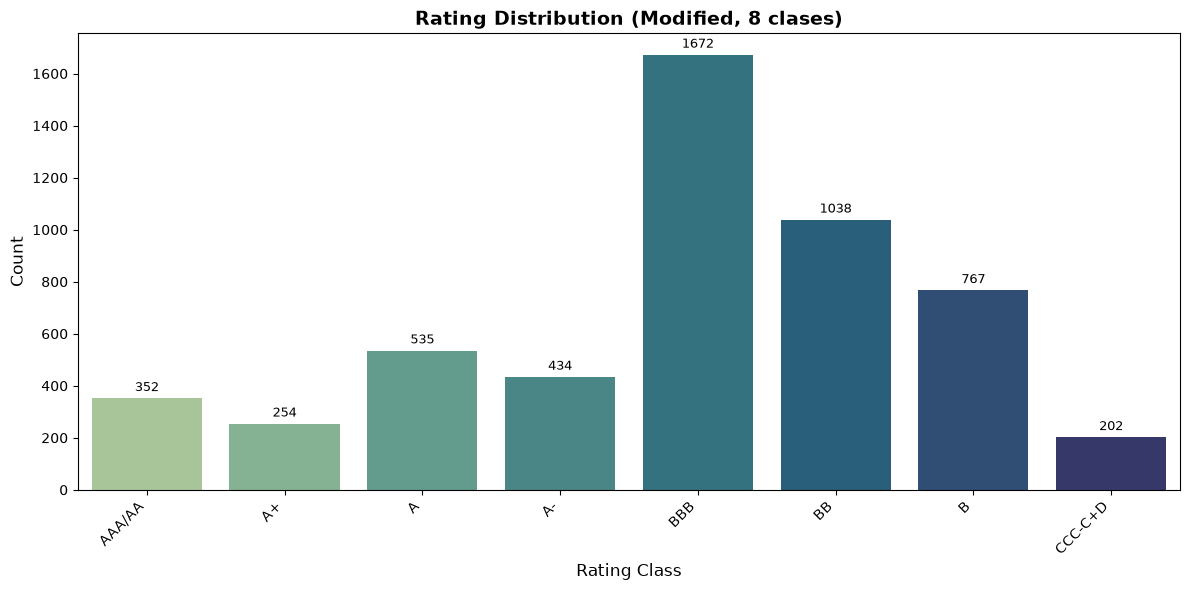

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.countplot(data=df, x=target, order=X_ORDER, hue=target, hue_order=X_ORDER,
              palette="crest", legend=False, ax=ax)
ax.set_title(f"Rating Distribution (Modified, {len(X_ORDER)} clases)", fontsize=14, fontweight='bold')
ax.set_xlabel("Rating Class", fontsize=12)
ax.set_ylabel("Count", fontsize=12)
ax.set_xticks(range(len(X_ORDER)))
ax.set_xticklabels(X_LABELS, rotation=45, ha='right')
for container in ax.containers:
    ax.bar_label(container, padding=3, fontsize=9)
plt.tight_layout()
plt.savefig('rating_distribution_modified.png')
plt.show()

### Mapa de calor variables

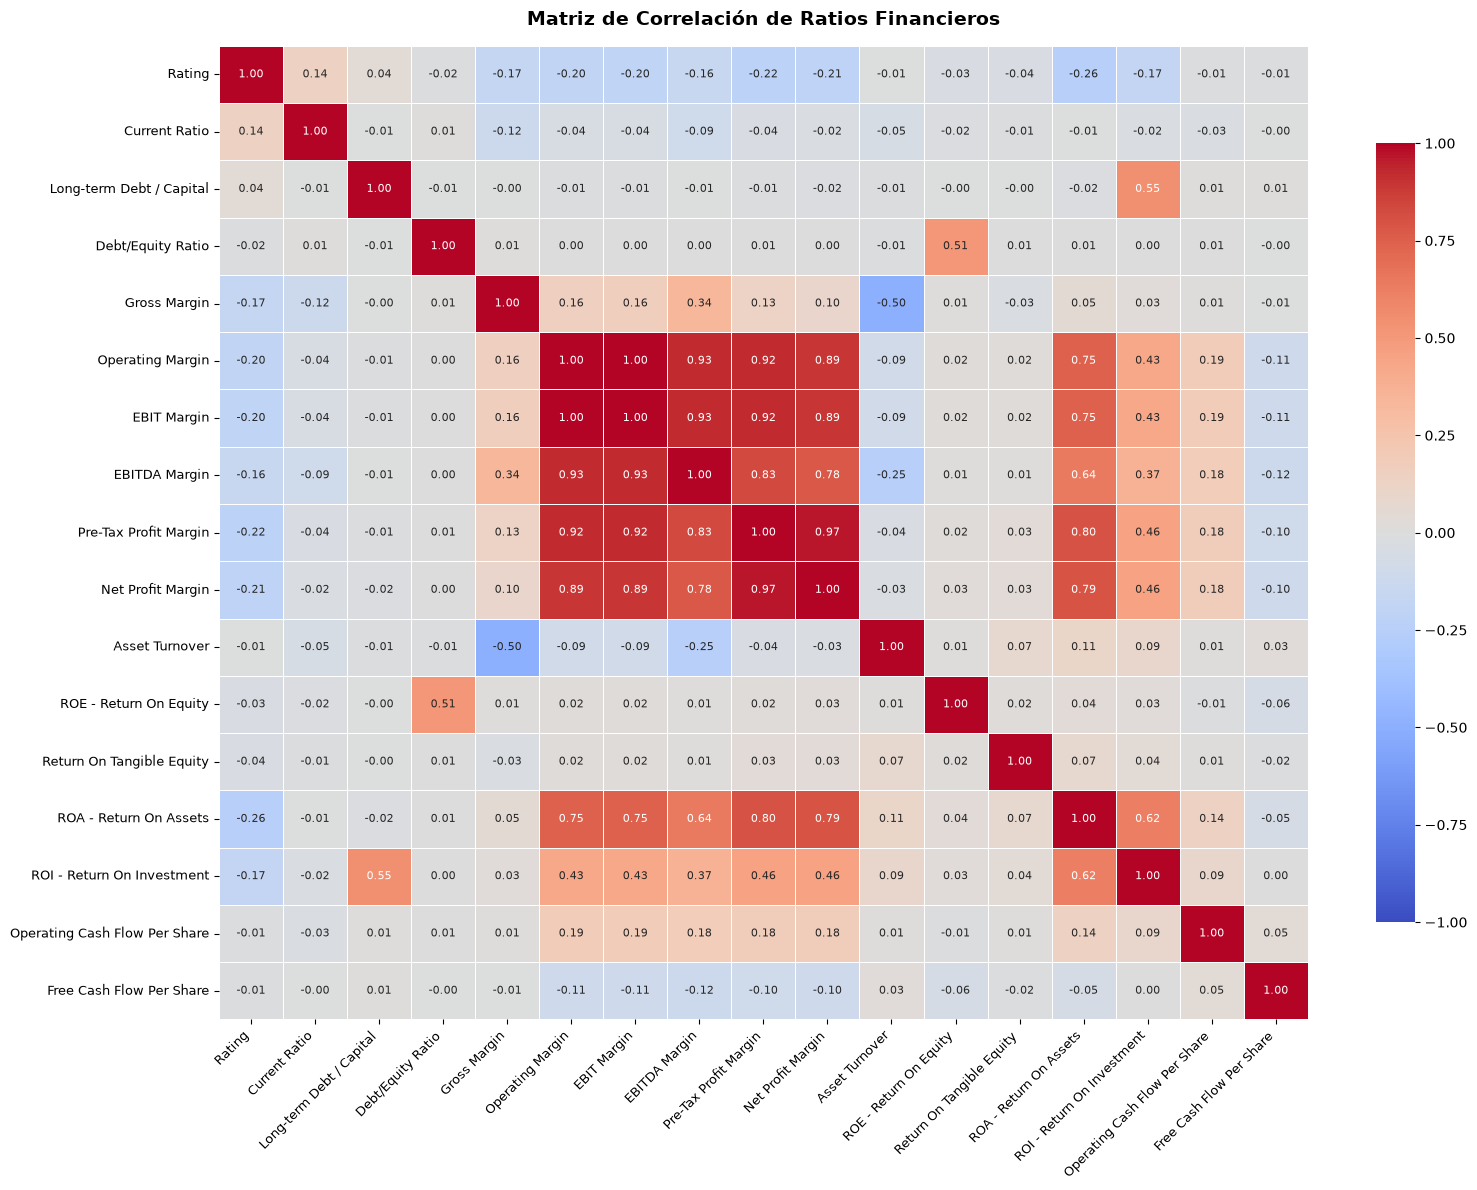

In [13]:
# 1. Ajuste de dimensiones del lienzo para albergar las ~16 variables numéricas
fig, ax = plt.subplots(figsize=(16, 12))

# 2. Matriz de correlación restringida a tipos numéricos
corr_matrix = df.select_dtypes(include='number').corr()

# 3. Mapa de calor con escala divergente y tamaño de fuente ajustado por celda
sns.heatmap(
    corr_matrix, 
    ax=ax, 
    annot=True, 
    fmt='.2f', 
    cmap='coolwarm', 
    vmin=-1, 
    vmax=1, 
    linewidths=0.5,
    annot_kws={"size": 8},
    cbar_kws={"shrink": 0.8}
)

# 4. Alineación y rotación de nombres de columnas para evitar superposición
ax.set_title("Matriz de Correlación de Ratios Financieros", fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()

## Keras

In [14]:
# 1. Extracción dinámica de dimensiones
input_dim = X_train_proc.shape[1]
num_classes = len(X_ORDER)
print(f"input_dim = {input_dim} | num_classes = {num_classes}")

input_dim = 33 | num_classes = 8


In [15]:
# 2. Definición de la Arquitectura Secuencial (MLP)
model = models.Sequential([
    # Capa de Entrada explícita
    layers.Input(shape=(input_dim,)),

    # Bloque Oculto 1: Extracción de representaciones de alto nivel
    layers.Dense(128, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.3),

    # Bloque Oculto 2: Compresión y abstracción de características
    layers.Dense(64, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.Dropout(0.2),
    
    # Bloque Oculto 3: 
    layers.Dense(32, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),

    # Bloque Oculto 4: Mapeo denso hacia el espacio de clasificación
    layers.Dense(16, kernel_regularizer=regularizers.l2(1e-4)),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    
    # Capa de Salida: 14 Logits lineales (sin Softmax explícito)
    layers.Dense(num_classes)
])

In [16]:
# 3. Compilación del Modelo
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['sparse_categorical_accuracy']
)
# Resumen de la arquitectura en consola
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,312 (63.72 KB)

 Trainable params: 15,832 (61.84 KB)

 Non-trainable params: 480 (1.88 KB)

In [17]:
# 4. Estrategia de Callbacks para Regularización Temporal
early_stopping = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=25,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=1e-5,
    verbose=1
)

## Entrenamiento, curvas y métricas

In [ ]:
# 5. Proceso de Entrenamiento y Validación
USAR_PESOS = False   # True -> class_weight balanceado

class_weight = None
if USAR_PESOS:
    from sklearn.utils.class_weight import compute_class_weight
    cw = compute_class_weight('balanced', classes=np.array(X_ORDER), y=y_train)
    class_weight = {c: w for c, w in zip(X_ORDER, cw)}
    print("class_weight:", {k: round(v, 2) for k, v in class_weight.items()})

history = modelo.fit(
    X_train_proc, 
    y_train,
    epochs=150,
    batch_size=32,
    validation_data=(X_val_proc, y_val),
    class_weight=pesos_clase_dict,  # <--- Este es el cambio fundamental
    verbose=1
)
test_loss, test_accuracy = model.evaluate(X_test_proc, y_test, verbose=0)
print(f"\n[EVALUACIÓN TEST FINAL]")
print(f"Pérdida en Test (val_ce): {test_loss:.4f}")
print(f"Exactitud Categórica en Test: {test_accuracy * 100:.2f}%")

Epoch 1/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 2.1940 - sparse_categorical_accuracy: 0.1449 - val_loss: 2.0665 - val_sparse_categorical_accuracy: 0.2648 - learning_rate: 0.0010
Epoch 2/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 2.0626 - sparse_categorical_accuracy: 0.2070 - val_loss: 2.0332 - val_sparse_categorical_accuracy: 0.3124 - learning_rate: 0.0010
Epoch 3/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 1.9774 - sparse_categorical_accuracy: 0.2463 - val_loss: 1.9966 - val_sparse_categorical_accuracy: 0.3257 - learning_rate: 0.0010
Epoch 4/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.9031 - sparse_categorical_accuracy: 0.2910 - val_loss: 1.9655 - val_sparse_categorical_accuracy: 0.3276 - learning_rate: 0.0010
Epoch 5/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.8562 - sparse_categorical_accuracy: 0.3198 - val_loss: 1.9319 - val_sparse_categorical_accuracy: 0.3371 - learning_rate: 0.0010
Epoch 6/100
17/17 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - l

              precision    recall  f1-score   support

      AAA/AA       0.48      0.34      0.40        35
          A+       0.26      0.20      0.23        25
           A       0.25      0.09      0.14        54
          A-       0.10      0.02      0.04        43
         BBB       0.46      0.67      0.55       168
          BB       0.37      0.49      0.42       104
           B       0.47      0.35      0.40        77
     CCC-C+D       0.50      0.30      0.38        20

    accuracy                           0.42       526
   macro avg       0.36      0.31      0.32       526
weighted avg       0.39      0.42      0.39       526

Macro-F1: 0.3182
Exactitud ±1 clase (adyacente): 77.57%


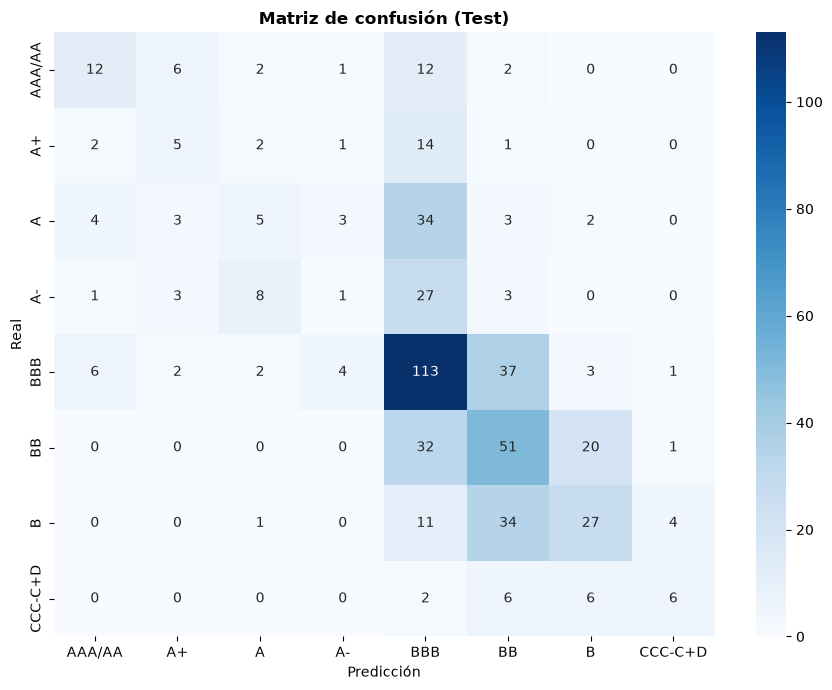

In [19]:
from sklearn.metrics import classification_report, confusion_matrix, f1_score

y_pred = np.argmax(model.predict(X_test_proc, verbose=0), axis=1)
y_true = y_test.to_numpy()

print(classification_report(y_true, y_pred, labels=X_ORDER, target_names=X_LABELS, zero_division=0))
print(f"Macro-F1: {f1_score(y_true, y_pred, average='macro', labels=X_ORDER, zero_division=0):.4f}")
print(f"Exactitud ±1 clase (adyacente): {(np.abs(y_true - y_pred) <= 1).mean() * 100:.2f}%")

cm = confusion_matrix(y_true, y_pred, labels=X_ORDER)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=X_LABELS, yticklabels=X_LABELS, ax=ax)
ax.set_xlabel("Predicción"); ax.set_ylabel("Real"); ax.set_title("Matriz de confusión (Test)", fontweight='bold')
plt.tight_layout()
plt.show()

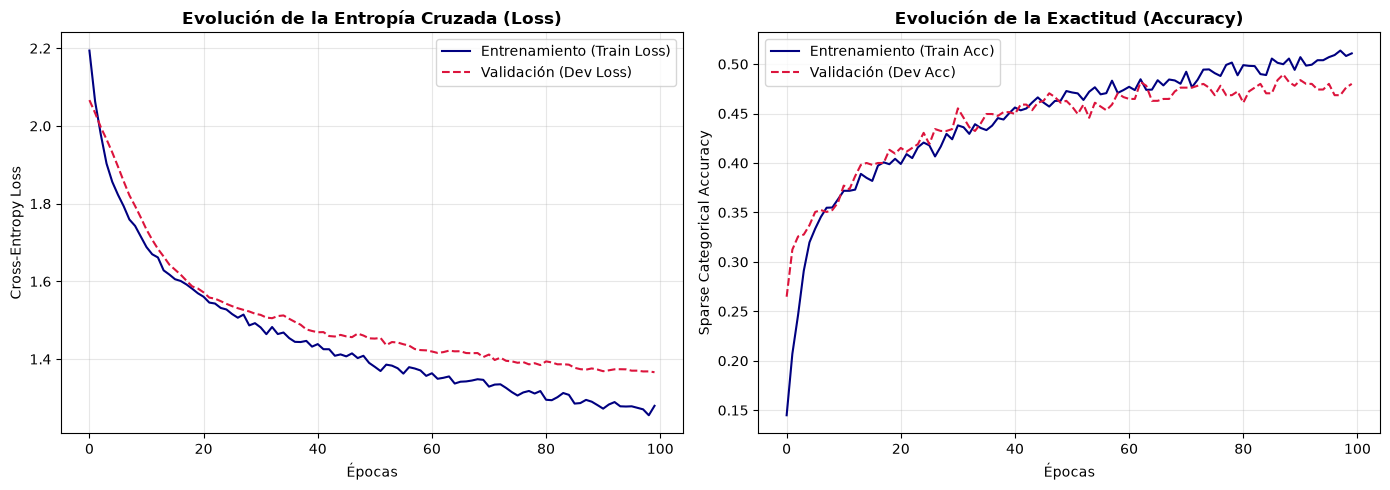

In [20]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Grafico de la Pérdida (Cross-Entropy)
ax1.plot(history.history['loss'], label='Entrenamiento (Train Loss)', color='navy')
ax1.plot(history.history['val_loss'], label='Validación (Dev Loss)', color='crimson', linestyle='--')
ax1.set_title("Evolución de la Entropía Cruzada (Loss)", fontweight='bold')
ax1.set_xlabel("Épocas")
ax1.set_ylabel("Cross-Entropy Loss")
ax1.legend()
ax1.grid(True, alpha=0.3)

# Gráfico de la Exactitud (Accuracy)
ax2.plot(history.history['sparse_categorical_accuracy'], label='Entrenamiento (Train Acc)', color='navy')
ax2.plot(history.history['val_sparse_categorical_accuracy'], label='Validación (Dev Acc)', color='crimson', linestyle='--')
ax2.set_title("Evolución de la Exactitud (Accuracy)", fontweight='bold')
ax2.set_xlabel("Épocas")
ax2.set_ylabel("Sparse Categorical Accuracy")
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Comparación de optimizadores manualmente

## Regularización y batch normalization

## Búsqueda aleatoria de hiperparámetros

## Evaluación final en Test y conclusiones